# 🛰️ Remote Sensing Change Detection — Google Colab Eğitim Defteri

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/osmankalkan/remote-sensing-change-detection/blob/main/notebooks/colab_train.ipynb)

LEVIR-CD-256 veri seti üzerinde değişim tespiti modelini **Colab T4 GPU** ile eğitir; ağırlıklar, loglar ve grafikler **Google Drive**'a kalıcı olarak kaydedilir.

## ⚡ Hızlı Başlangıç (Tek Tıkla Eğitim)
1. **GPU seç:** `Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU`
2. **`Çalışma zamanı → Tümünü çalıştır` (Run all)**

> 💡 **Veri seti için Kaggle token şart değildir!** Varsayılan olarak açık Hugging Face sunucusundan (`satellite-image-deep-learning/LEVIR-CD`) doğrudan indirilir (token/giriş gerekmez, 403 hatası vermez).
> İstersen 0. adımda Kaggle'ı da seçebilirsin; Kaggle başarısız olursa sistem otomatik olarak Hugging Face'e geçip eğitimi sürdürür.
> Colab bağlantısı koparsa tekrar **Run all** yapman yeterlidir (`RESUME=True` iken eğitim Drive'daki son checkpoint'ten devam eder).

| Adım | İçerik |
|---|---|
| 0 | ⚙️ Ayarlar (model, veri kaynağı, epoch, batch size…) |
| 1 | GPU kontrolü |
| 2 | Google Drive bağlantısı (başarısız olursa yerel diske düşer) |
| 3 | GitHub deposunu klonla / güncelle |
| 4 | Kütüphaneleri kur |
| 5 | Veri setini indir + 256x256 düzenle + doğrula (Sıfır Hata Garantili) |
| 6 | Eğitim konfigürasyonu |
| 7 | Eğitimi arka planda başlat |
| 8 | Canlı log takibi |
| 9 | Sonuçlar, grafikler ve görseller |
| 10 | Test seti değerlendirmesi |
| 11 | Yardımcı araçlar (durdur / GPU / log) |

## 0. ⚙️ Ayarlar
Tüm ayarlar burada. Diğer hücreler **yalnızca bu hücreye** bağımlıdır.

In [3]:
# @title ⚙️ Eğitim Ayarları { display-mode: "form" }
import os, sys, json, time, signal, subprocess

DATA_SOURCE = "huggingface"           # @param ["huggingface", "kaggle_256", "kaggle_official"]
MODEL_TYPE  = "baseline_early_fusion"  # @param ["baseline_early_fusion", "siamese_unet"]
ENCODER     = "resnet18"               # @param ["resnet18", "resnet34", "resnet50", "efficientnet-b0"]
EPOCHS      = 30                       # @param {type:"integer"}
BATCH_SIZE  = 16                       # @param {type:"integer"}
LR          = 0.0003                   # @param {type:"number"}
LOSS        = "bce_dice"               # @param ["bce_dice", "focal_dice", "bce", "dice", "focal"]
USE_DRIVE   = True                     # @param {type:"boolean"}
RESUME      = True                     # @param {type:"boolean"}

REPO_URL    = "https://github.com/osmankalkan/remote-sensing-change-detection.git"
BRANCH      = "main"

# ---- Yollar ----
REPO_DIR       = "/content/remote-sensing-change-detection"
DATA_DIR       = os.path.join(REPO_DIR, "data", "processed")
CONFIG_PATH    = os.path.join(REPO_DIR, "configs", "config_colab.yaml")
RUN_NAME       = f"{MODEL_TYPE}_{ENCODER}"
DRIVE_ROOT     = "/content/drive/MyDrive/remote_sensing_change_detection"
LOCAL_SAVE_DIR = os.path.join("/content/checkpoints", RUN_NAME)
SAVE_DIR       = LOCAL_SAVE_DIR          # 2. adımda Drive bağlanırsa Drive yolu ile değiştirilir
LOG_DIR        = "/content/train_logs"
LOG_PATH       = os.path.join(LOG_DIR, f"{RUN_NAME}.log")
PID_PATH       = os.path.join(LOG_DIR, f"{RUN_NAME}.pid")
os.makedirs(LOG_DIR, exist_ok=True)


# ---- Yardımcı fonksiyonlar ----
def run(cmd, cwd=None, check=True, quiet=False):
    r = subprocess.run(cmd, shell=isinstance(cmd, str), cwd=cwd, capture_output=True, text=True)
    if not quiet and r.stdout.strip():
        print(r.stdout.strip()[-4000:])
    if r.returncode != 0:
        print(r.stderr.strip()[-4000:])
        if check:
            raise RuntimeError(f"Komut başarısız oldu (exit {r.returncode}): {cmd}")
    return r


def is_running(pid):
    if not pid:
        return False
    try:
        with open(f"/proc/{pid}/stat") as f:
            state = f.read().split(")")[-1].split()[0]
        if state == "Z":
            try:
                os.waitpid(pid, os.WNOHANG)
            except ChildProcessError:
                pass
            return False
        with open(f"/proc/{pid}/cmdline", "rb") as f:
            return b"train.py" in f.read()
    except (FileNotFoundError, ProcessLookupError, IndexError):
        return False


def read_pid():
    try:
        with open(PID_PATH) as f:
            return int(f.read().strip())
    except (FileNotFoundError, ValueError):
        return None


def sync_log_to_save_dir():
    if os.path.exists(LOG_PATH) and os.path.isdir(SAVE_DIR):
        try:
            import shutil
            shutil.copy(LOG_PATH, os.path.join(SAVE_DIR, "train.log"))
        except Exception as e:
            print(f"(log kopyalanamadı: {e})")


print("✅ Ayarlar yüklendi")
print(f"   Veri Kaynağı: {DATA_SOURCE} {'(Token GEREKMEZ 🚀)' if DATA_SOURCE == 'huggingface' else '(Kaggle)'}")
print(f"   Model       : {MODEL_TYPE} / {ENCODER}")
print(f"   Epoch       : {EPOCHS} | Batch: {BATCH_SIZE} | LR: {LR} | Loss: {LOSS}")
print(f"   Drive       : {'açık' if USE_DRIVE else 'kapalı'} | Resume: {RESUME}")
print(f"   Çalışma adı : {RUN_NAME}")

✅ Ayarlar yüklendi
   Veri Kaynağı: huggingface (Token GEREKMEZ 🚀)
   Model       : baseline_early_fusion / resnet18
   Epoch       : 30 | Batch: 16 | LR: 0.0003 | Loss: bce_dice
   Drive       : açık | Resume: True
   Çalışma adı : baseline_early_fusion_resnet18


## 1. GPU Kontrolü

In [4]:
import torch

assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."
print("=" * 60)
print(f"PyTorch {torch.__version__} | CUDA {torch.version.cuda}")
if torch.cuda.is_available():
    name = torch.cuda.get_device_name(0)
    vram = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"✅ GPU: {name} ({vram:.1f} GB VRAM)")
    run("nvidia-smi --query-gpu=name,memory.used,memory.total,utilization.gpu --format=csv")
else:
    raise RuntimeError(
        "❌ GPU bulunamadı! Menüden: Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU "
        "seçip 'Kaydet' de, sonra defteri baştan çalıştır."
    )

PyTorch 2.11.0+cu130 | CUDA 13.0
✅ GPU: Tesla T4 (14.6 GB VRAM)
name, memory.used [MiB], memory.total [MiB], utilization.gpu [%]
Tesla T4, 3 MiB, 15360 MiB, 0 %


## 2. Google Drive Bağlantısı
Ağırlıklar ve grafikler Drive'a yazılır, böylece Colab oturumu kapansa da kaybolmaz.
Bağlantı **başarısız olursa** hücre hata vermez; kayıtlar yerel diske (`/content/checkpoints`) yapılır.

In [5]:
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."
SAVE_DIR = LOCAL_SAVE_DIR

if USE_DRIVE:
    try:
        from google.colab import drive
        if os.path.ismount("/content/drive"):
            print("ℹ️ Drive zaten bağlı.")
        else:
            try:
                drive.mount("/content/drive")
            except Exception as first_err:
                print(f"⚠️ İlk deneme başarısız ({first_err}); force_remount ile tekrar deneniyor...")
                drive.mount("/content/drive", force_remount=True)

        drive_save_dir = os.path.join(DRIVE_ROOT, "checkpoints", RUN_NAME)
        os.makedirs(drive_save_dir, exist_ok=True)
        probe = os.path.join(drive_save_dir, ".write_test")
        with open(probe, "w") as f:
            f.write("ok")
        os.remove(probe)
        SAVE_DIR = drive_save_dir
        print("✅ Google Drive bağlandı ve yazılabilir.")
    except Exception as e:
        print(f"⚠️ Google Drive kullanılamıyor: {type(e).__name__}: {e}")
        print("   → Kayıtlar yerel diske yapılacak (oturum kapanınca silinir!). Sonra Drive'a elle kopyalayabilirsin.")
else:
    print("ℹ️ USE_DRIVE=False → yerel disk kullanılıyor.")

os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(os.path.join(SAVE_DIR, "visualizations"), exist_ok=True)
print(f"📁 Kayıt dizini: {SAVE_DIR}")

⚠️ İlk deneme başarısız (Error: credential propagation was unsuccessful); force_remount ile tekrar deneniyor...
⚠️ Google Drive kullanılamıyor: MessageError: Error: credential propagation was unsuccessful
   → Kayıtlar yerel diske yapılacak (oturum kapanınca silinir!). Sonra Drive'a elle kopyalayabilirsin.
📁 Kayıt dizini: /content/checkpoints/baseline_early_fusion_resnet18


## 3. GitHub Deposunu Klonla / Güncelle

In [6]:
import shutil
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."
os.chdir("/content")

if os.path.isdir(os.path.join(REPO_DIR, ".git")):
    print(f"🔄 Depo mevcut, güncelleniyor ({BRANCH})...")
    run(["git", "fetch", "--depth", "1", "origin", BRANCH], cwd=REPO_DIR)
    run(["git", "reset", "--hard", f"origin/{BRANCH}"], cwd=REPO_DIR)
else:
    if os.path.exists(REPO_DIR):
        print("⚠️ Klasör var ama git deposu değil, siliniyor...")
        shutil.rmtree(REPO_DIR)
    print(f"📥 Klonlanıyor: {REPO_URL}")
    run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, REPO_DIR])

os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
run(["git", "log", "-1", "--format=✅ Son commit: %h  %s  (%cr)"], cwd=REPO_DIR)
print(f"📂 Çalışma dizini: {os.getcwd()}")

📥 Klonlanıyor: https://github.com/osmankalkan/remote-sensing-change-detection.git
✅ Son commit: 02b25f8  fix(data): resolve Kaggle 403 error with zero-token Hugging Face download and auto-slicing  (9 days ago)
📂 Çalışma dizini: /content/remote-sensing-change-detection


## 4. Kütüphanelerin Kurulumu
Colab'de PyTorch, OpenCV, NumPy zaten kurulu. Onlara dokunulmaz; eksikler kurulur.

In [7]:
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."
print("📦 Eksik kütüphaneler kuruluyor...")
run([sys.executable, "-m", "pip", "install", "-q",
     "segmentation-models-pytorch>=0.3.3", "albumentations>=1.4.0", "pyyaml", "tqdm"])
run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"])

check = run([sys.executable, "-c", (
    "import torch, torchvision, cv2, numpy, albumentations as A, segmentation_models_pytorch as smp;"
    "print(f' - torch {torch.__version__} | torchvision {torchvision.__version__} | numpy {numpy.__version__}');"
    "print(f' - smp {smp.__version__} | albumentations {A.__version__} | opencv {cv2.__version__}')"
)], quiet=True)
print("✅ Kurulum tamam:")
print(check.stdout)

📦 Eksik kütüphaneler kuruluyor...
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.3 MB/s eta 0:00:00
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.9 MB/s eta 0:00:00
✅ Kurulum tamam:
 - torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | numpy 2.1.3
 - smp 0.5.0 | albumentations 2.0.8 | opencv 4.14.0



## 5. Veri Seti (LEVIR-CD-256) — Sıfır Hata Garantili
- **Token gerektirmez:** `DATA_SOURCE="huggingface"` seçiliyse hiçbir şifre, token veya onay gerekmeden açık sunucudan indirilir.
- **Kaggle seçilirse:** Kaggle denenir; 403 veya token hatası olursa **otomatik olarak Hugging Face'e geçilir**, süreç asla durmaz.
- İnen görüntüler 1024x1024 ise otomatik olarak 256x256 patch'lere dilimlenir (`scripts/prepare_kaggle_levir.py`).

In [8]:
import shutil, glob, zipfile
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."
os.chdir(REPO_DIR)
PREP = [sys.executable, "scripts/prepare_kaggle_levir.py", "--dst", DATA_DIR]


def dataset_ready():
    return subprocess.run(PREP + ["--verify_only"], capture_output=True, text=True).returncode == 0


def try_setup_kaggle():
    try:
        from google.colab import userdata
        for key in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
            try:
                val = userdata.get(key)
                if val:
                    os.environ[key] = val.strip()
            except Exception:
                pass
    except ImportError:
        pass
    if os.environ.get("KAGGLE_API_TOKEN"):
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        p = os.path.expanduser("~/.kaggle/access_token")
        with open(p, "w") as f:
            f.write(os.environ["KAGGLE_API_TOKEN"])
        os.chmod(p, 0o600)
        return True
    return bool(os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")) or            os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json"))


if dataset_ready():
    print("ℹ️ Veri seti zaten hazır, indirme atlandı.")
else:
    tmp = "/content/data_temp"
    shutil.rmtree(tmp, ignore_errors=True)
    shutil.rmtree(DATA_DIR, ignore_errors=True)
    os.makedirs(tmp, exist_ok=True)

    downloaded = False

    # 1. Kullanıcı Kaggle seçtiyse Kaggle'ı dene
    if DATA_SOURCE != "huggingface":
        k_name = "strangefacts/levir-cd256" if DATA_SOURCE == "kaggle_256" else "mdrifaturrahman33/levir-cd"
        if try_setup_kaggle():
            print(f"🚀 Kaggle'dan indiriliyor: {k_name}...")
            r = subprocess.run(["kaggle", "datasets", "download", "-d", k_name, "-p", tmp, "--unzip"],
                               capture_output=True, text=True)
            if r.returncode == 0:
                downloaded = True
                print("✅ Kaggle indirmesi tamamlandı.")
            else:
                print(f"⚠️ Kaggle CLI başarısız oldu (403 veya token hatası):\n{r.stderr[-500:]}")
        else:
            print("ℹ️ Kaggle kimlik bilgisi bulunamadı.")

    # 2. Kaggle seçilmediyse veya Kaggle hata verdiyse -> Hugging Face DOĞRUDAN İNDİR (Token GEREKMEZ)
    if not downloaded:
        if DATA_SOURCE != "huggingface":
            print("\n🔁 Kaggle kullanılamadı. Otomatik olarak açık Hugging Face sunucusuna geçiliyor (token gerekmez)...")
        print("🚀 Hugging Face'ten LEVIR-CD indiriliyor ve açılıyor (satellite-image-deep-learning/LEVIR-CD)...")
        r = subprocess.run(PREP + ["--download_hf", "--src", tmp], capture_output=False)
        downloaded = True

    # 3. İndirilen verileri kontrol et ve 256x256 patch yapısına organize et
    if downloaded and not dataset_ready():
        # Varsa zip'leri aç
        for z in glob.glob(os.path.join(tmp, "**", "*.zip"), recursive=True):
            with zipfile.ZipFile(z) as zf:
                zf.extractall(os.path.dirname(z))
            os.remove(z)
        print("🚚 Klasör yapısı düzenleniyor ve gerekirse 256x256 patch'lere dilimleniyor...")
        r = subprocess.run(PREP + ["--src", tmp], capture_output=True, text=True)
        print(r.stdout)
        if r.returncode != 0:
            print(r.stderr[-2000:])
            raise RuntimeError("❌ Veri seti düzenlenemedi.")

    shutil.rmtree(tmp, ignore_errors=True)

# Son doğrulama raporu
print(subprocess.run(PREP + ["--verify_only"], capture_output=True, text=True).stdout)

🚀 Hugging Face'ten LEVIR-CD indiriliyor ve açılıyor (satellite-image-deep-learning/LEVIR-CD)...
DATASET REPORT (/content/remote-sensing-change-detection/data/processed)
[TRAIN] A:   7120 | B:   7120 | label:   7120 | complete triplets:   7120  -> OK
[VAL  ] A:   1024 | B:   1024 | label:   1024 | complete triplets:   1024  -> OK
[TEST ] A:   2048 | B:   2048 | label:   2048 | complete triplets:   2048  -> OK
[OK] Dataset is ready for training.



## 6. Eğitim Konfigürasyonu
`configs/config.yaml` temel alınır, 0. hücredeki ayarlar uygulanır ve `configs/config_colab.yaml` yazılır.

In [9]:
import yaml
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."
os.chdir(REPO_DIR)

with open(os.path.join(REPO_DIR, "configs", "config.yaml")) as f:
    config = yaml.safe_load(f)

config["data"]["processed_dir"]       = DATA_DIR
config["data"]["num_workers"]         = max(1, min(4, os.cpu_count() or 2))
config["model"]["type"]               = MODEL_TYPE
config["model"]["encoder_name"]       = ENCODER
config["training"]["device"]          = "cuda"
config["training"]["epochs"]          = int(EPOCHS)
config["training"]["batch_size"]      = int(BATCH_SIZE)
config["training"]["lr"]              = float(LR)
config["training"]["loss"]            = LOSS
config["training"]["mixed_precision"] = True
config["training"]["save_dir"]        = SAVE_DIR
config["project"]["experiment_name"]  = RUN_NAME

with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(config, f, default_flow_style=False, sort_keys=False)

print(f"✅ Konfigürasyon yazıldı: {CONFIG_PATH}\n")
print(yaml.safe_dump({k: config[k] for k in ("model", "training")}, sort_keys=False))
print(f"num_workers: {config['data']['num_workers']}")

✅ Konfigürasyon yazıldı: /content/remote-sensing-change-detection/configs/config_colab.yaml

model:
  type: baseline_early_fusion
  encoder_name: resnet18
  encoder_weights: imagenet
  in_channels: 6
  classes: 1
training:
  batch_size: 16
  epochs: 30
  lr: 0.0003
  weight_decay: 0.0001
  loss: bce_dice
  bce_weight: 0.5
  dice_weight: 0.5
  focal_gamma: 2.0
  device: cuda
  mixed_precision: true
  save_dir: /content/checkpoints/baseline_early_fusion_resnet18

num_workers: 2


## 7. Eğitimi Arka Planda Başlat
Eğitim **ayrı bir süreçte** çalışır: bu hücreyi veya 8. hücreyi durdurmak eğitimi **durdurmaz**.
- `RESUME=True` ve Drive'da `latest_model.pth` varsa **kaldığı epoch'tan devam eder**.
- Zaten çalışan bir eğitim varsa ikinci kez başlatılmaz.

In [10]:
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."
assert os.path.exists(CONFIG_PATH), "Önce 6. hücreyi çalıştır (config_colab.yaml yok)."
os.chdir(REPO_DIR)

existing = read_pid()
if is_running(existing):
    print(f"ℹ️ Eğitim zaten çalışıyor (PID {existing}). 8. hücreden takip edebilirsin.")
else:
    resume_possible = RESUME and os.path.exists(os.path.join(SAVE_DIR, "latest_model.pth"))
    cmd = [sys.executable, "-u", "src/train.py", "--config", CONFIG_PATH]
    if RESUME:
        cmd.append("--resume")

    log_f = open(LOG_PATH, "a" if resume_possible else "w")
    log_f.write(f"\n===== {time.strftime('%Y-%m-%d %H:%M:%S')} | {' '.join(cmd)} =====\n")
    log_f.flush()
    env = dict(os.environ, MPLBACKEND="Agg", PYTHONUNBUFFERED="1")
    proc = subprocess.Popen(cmd, cwd=REPO_DIR, stdout=log_f, stderr=subprocess.STDOUT,
                            env=env, start_new_session=True)
    with open(PID_PATH, "w") as f:
        f.write(str(proc.pid))
    print(f"🚀 Eğitim başlatıldı (PID {proc.pid}){' — checkpoint’ten devam ediliyor' if resume_possible else ''}")
    print("   Model kuruluyor ve veri yükleniyor, ilk kontrol yapılıyor...")

    started = False
    for _ in range(120):
        time.sleep(1)
        with open(LOG_PATH) as f:
            log_text = f.read()
        if "Nothing to do" in log_text.split("=====")[-1]:
            print("ℹ️ Bu çalışma zaten tamamlanmış. Yeniden eğitmek için 0. hücrede RESUME=False yap "
                  "veya EPOCHS değerini artır.")
            started = None
            break
        if proc.poll() is not None:
            break
        if "Commencing training" in log_text:
            started = True
            break

    if started:
        print("✅ Eğitim çalışıyor! (8. hücreden canlı takip et)")
        print(f"📝 Log : {LOG_PATH}")
        print(f"💾 Ağırlıklar: {SAVE_DIR}/best_model.pth")
    elif started is False:
        print("\n" + "=" * 60 + "\n❌ EĞİTİM BAŞLATILAMADI — log çıktısı:\n" + "=" * 60)
        with open(LOG_PATH) as f:
            print(f.read()[-6000:])
        if proc.poll() is not None:
            raise RuntimeError("Eğitim süreci hata ile kapandı (yukarıdaki log'a bak).")
        print("ℹ️ Süreç hâlâ çalışıyor ama henüz başlamadı; 8. hücreden takip et.")

🚀 Eğitim başlatıldı (PID 1895)
   Model kuruluyor ve veri yükleniyor, ilk kontrol yapılıyor...
✅ Eğitim çalışıyor! (8. hücreden canlı takip et)
📝 Log : /content/train_logs/baseline_early_fusion_resnet18.log
💾 Ağırlıklar: /content/checkpoints/baseline_early_fusion_resnet18/best_model.pth


## 8. Canlı Eğitim Takibi
Log'u canlı gösterir ve eğitim bitince kendiliğinden durur.
> 💡 Bu hücreyi durdurmak (⏹) eğitimi **durdurmaz**; istediğin zaman tekrar çalıştırabilirsin.

In [11]:
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."
pid = read_pid()
if not os.path.exists(LOG_PATH):
    print("ℹ️ Henüz log yok. Önce 7. hücreyi çalıştır.")
else:
    print(f"👀 Canlı log (PID {pid}) — durdurmak için ⏹\n" + "-" * 70)
    last_sync = time.time()
    try:
        with open(LOG_PATH) as f:
            while True:
                line = f.readline()
                if line:
                    print(line, end="")
                    continue
                if not is_running(pid):
                    rest = f.read()
                    if rest:
                        print(rest, end="")
                    break
                if time.time() - last_sync > 300:
                    sync_log_to_save_dir()
                    last_sync = time.time()
                time.sleep(2)
        sync_log_to_save_dir()
        with open(LOG_PATH) as f:
            tail = f.read().split("=====")[-1]
        print("\n" + "=" * 70)
        if "[Finished]" in tail or "Nothing to do" in tail:
            print("🏁 Eğitim başarıyla tamamlandı! 9. hücreye geç.")
        elif "Traceback" in tail or "Error" in tail:
            print("❌ Eğitim hata ile durdu. Yukarıdaki 'Traceback' kısmına bak.")
            if "out of memory" in tail.lower():
                print("💡 GPU belleği yetmedi → 0. hücrede BATCH_SIZE'ı düşür (örn. 8), sonra 6 ve 7'yi tekrar çalıştır.")
            print("💡 RESUME=True ise 7. hücreyi tekrar çalıştırınca son checkpoint'ten devam eder.")
        else:
            print("⏹ Eğitim süreci sonlandı (durdurulmuş olabilir).")
        print("=" * 70)
    except KeyboardInterrupt:
        sync_log_to_save_dir()
        print("\n\n⏸️ Takip durduruldu — eğitim arka planda devam ediyor.")

👀 Canlı log (PID 1895) — durdurmak için ⏹
----------------------------------------------------------------------

===== 2026-10-21 07:46:34 | /usr/bin/python3 -u src/train.py --config /content/remote-sensing-change-detection/configs/config_colab.yaml --resume =====
[Device] Using CUDA GPU: Tesla T4
[Training] Using compute device: cuda
[Dataset] Train samples: 7120 | Val samples: 1024
[Dataset] Train batches/epoch: 445 | Val batches: 64
[Model] Building Baseline Early Fusion U-Net (resnet18)...
[Model] Parameters: 14.34M
[Training] Mixed precision (AMP fp16): ON
[Resume] No checkpoint found at /content/checkpoints/baseline_early_fusion_resnet18/latest_model.pth, starting from scratch.

[Training] Commencing training for epochs 1..30
[Output] Checkpoints and logs will be saved to: /content/checkpoints/baseline_early_fusion_resnet18
  [Train] 89/445 ( 20.0%) | loss: 0.5521 | 23s
  [Train] 178/445 ( 40.0%) | loss: 0.3934 | 37s
  [Train] 267/445 ( 60.0%) | loss: 0.3983 | 52s
  [Train] 356/

## 9. Sonuçlar: Checkpoint, Eğitim Grafikleri ve Tahmin Görselleri

🔍 CHECKPOINT RAPORU — /content/checkpoints/baseline_early_fusion_resnet18
✅ best_model.pth (164.3 MB) — epoch 29
   Val IoU 0.7959 | F1 0.8863 | Precision 0.8969 | Recall 0.8761


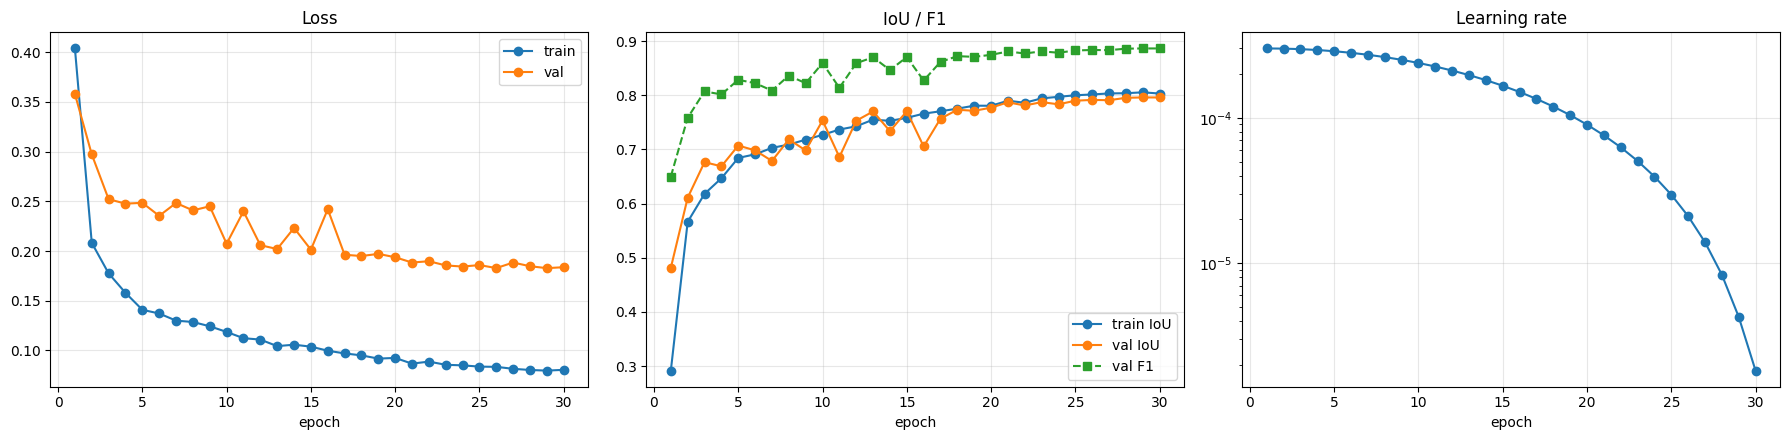

 epoch       lr  train_loss  val_loss  train_iou  train_f1  val_iou   val_f1  val_precision  val_recall  time_s
    26 0.000021    0.083494  0.182842   0.801379  0.889739 0.791340 0.883517       0.888590    0.878503    81.7
    27 0.000014    0.081511  0.188403   0.803302  0.890923 0.790781 0.883169       0.901678    0.865404    81.3
    28 0.000008    0.080340  0.184695   0.803715  0.891177 0.795225 0.885934       0.897845    0.874334    82.3
    29 0.000004    0.079704  0.182776   0.805309  0.892156 0.795892 0.886348       0.896873    0.876066    81.9
    30 0.000002    0.080503  0.183713   0.803136  0.890821 0.795855 0.886324       0.897817    0.875123    81.9


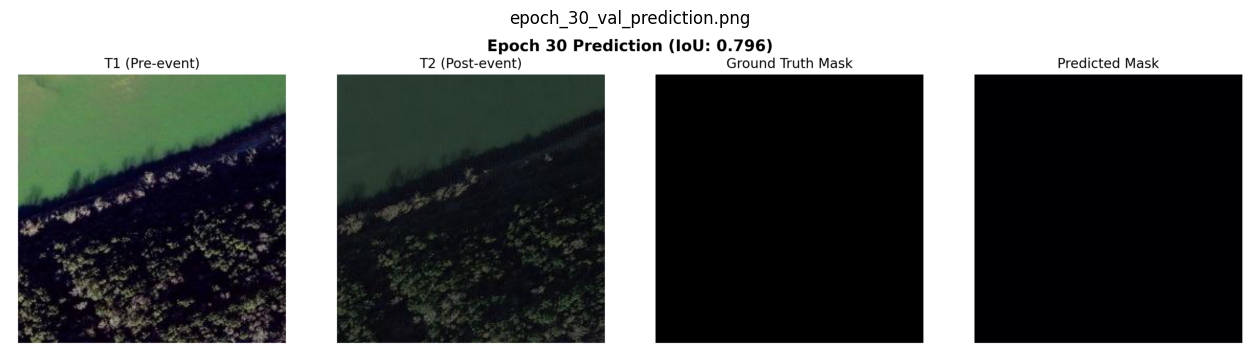

In [12]:
import glob, torch
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."

best_path = os.path.join(SAVE_DIR, "best_model.pth")
print("=" * 65 + f"\n🔍 CHECKPOINT RAPORU — {SAVE_DIR}\n" + "=" * 65)
if os.path.exists(best_path):
    ckpt = torch.load(best_path, map_location="cpu", weights_only=False)
    s = ckpt.get("val_scores", {})
    print(f"✅ best_model.pth ({os.path.getsize(best_path) / 1024**2:.1f} MB) — epoch {ckpt.get('epoch')}")
    print(f"   Val IoU {s.get('iou', 0):.4f} | F1 {s.get('f1', 0):.4f} | "
          f"Precision {s.get('precision', 0):.4f} | Recall {s.get('recall', 0):.4f}")
else:
    print("⏳ best_model.pth henüz yok (ilk epoch bitmemiş olabilir).")

hist_path = os.path.join(SAVE_DIR, "history.csv")
if os.path.exists(hist_path):
    h = pd.read_csv(hist_path)
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    ax[0].plot(h.epoch, h.train_loss, "o-", label="train"); ax[0].plot(h.epoch, h.val_loss, "o-", label="val")
    ax[0].set_title("Loss"); ax[0].legend()
    ax[1].plot(h.epoch, h.train_iou, "o-", label="train IoU"); ax[1].plot(h.epoch, h.val_iou, "o-", label="val IoU")
    ax[1].plot(h.epoch, h.val_f1, "s--", label="val F1"); ax[1].set_title("IoU / F1"); ax[1].legend()
    ax[2].plot(h.epoch, h.lr, "o-"); ax[2].set_title("Learning rate"); ax[2].set_yscale("log")
    for a in ax:
        a.set_xlabel("epoch"); a.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, "training_curves.png"), dpi=120)
    plt.show()
    print(h.tail(5).to_string(index=False))

vis = sorted(glob.glob(os.path.join(SAVE_DIR, "visualizations", "*.png")))
if vis:
    plt.figure(figsize=(16, 5))
    plt.imshow(mpimg.imread(vis[-1])); plt.axis("off"); plt.title(os.path.basename(vis[-1]))
    plt.show()
else:
    print("ℹ️ Henüz görselleştirme yok (1., her 5. ve son epoch'ta kaydedilir).")

## 10. Test Seti Değerlendirmesi

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.datasets import DualAugmentationDataset, get_transforms
from src.metrics import ChangeDetectionMetrics
from src.train import build_model

best_path = os.path.join(SAVE_DIR, "best_model.pth")
if is_running(read_pid()):
    print("⚠️ Eğitim hâlâ çalışıyor — bitince bu hücreyi çalıştır (GPU paylaşımı eğitimi yavaşlatır).")
elif not os.path.exists(best_path):
    print("⏳ best_model.pth bulunamadı.")
elif not os.path.isdir(os.path.join(DATA_DIR, "test", "A")):
    print("ℹ️ Test bölümü yok.")
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(best_path, map_location="cpu", weights_only=False)
    m_cfg = dict(ckpt["config"]["model"]); m_cfg["encoder_weights"] = None
    model = build_model(m_cfg)
    model.load_state_dict(ckpt["model_state_dict"])
    model.to(device).eval()

    ds = DualAugmentationDataset(DATA_DIR, split="test", transforms=get_transforms("test"))
    dl = DataLoader(ds, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)
    metrics, examples = ChangeDetectionMetrics(), []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
        for b in dl:
            logits = model(b["t1"].to(device), b["t2"].to(device)).float()
            metrics.update(logits, b["mask"].to(device))
            if len(examples) < 4:
                probs = torch.sigmoid(logits).cpu().numpy()
                for i in range(len(probs)):
                    if b["raw_mask"][i].sum() > 500 and len(examples) < 4:
                        examples.append((b["raw_t1"][i].numpy(), b["raw_t2"][i].numpy(),
                                         b["raw_mask"][i].numpy(), probs[i, 0]))
    s = metrics.compute()
    print("=" * 60 + f"\n🧪 TEST SONUÇLARI ({len(ds)} görüntü) — epoch {ckpt.get('epoch')}\n" + "=" * 60)
    for k in ("iou", "f1", "precision", "recall", "oa"):
        print(f"   {k.upper():10s}: {s[k]:.4f}")
    import json as _json
    with open(os.path.join(SAVE_DIR, "test_metrics.json"), "w") as f:
        _json.dump(s, f, indent=2)

    if examples:
        fig, ax = plt.subplots(len(examples), 4, figsize=(14, 3.5 * len(examples)))
        ax = np.atleast_2d(ax)
        for r, (a, b_, gt, p) in enumerate(examples):
            for c, (img, t) in enumerate([(a, "T1"), (b_, "T2"), (gt, "Gerçek"), (p > 0.5, "Tahmin")]):
                ax[r, c].imshow(img, cmap=None if c < 2 else "gray"); ax[r, c].set_title(t); ax[r, c].axis("off")
        plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, "test_examples.png"), dpi=120); plt.show()

[Model] Building Baseline Early Fusion U-Net (resnet18)...
🧪 TEST SONUÇLARI (2048 görüntü) — epoch 29
   IOU       : 0.7964
   F1        : 0.8866
   PRECISION : 0.8965
   RECALL    : 0.8770
   OA        : 0.9886


## 11. Yardımcı Araçlar

In [14]:
# @title 🧰 Araçlar { display-mode: "form" }
STOP_TRAINING = False  # @param {type:"boolean"}
SHOW_GPU      = True   # @param {type:"boolean"}
SHOW_LOG_TAIL = True   # @param {type:"boolean"}
assert "REPO_DIR" in globals(), "Önce 0. hücreyi (Ayarlar) çalıştır."

pid = read_pid()
print(f"Eğitim durumu: {'🟢 çalışıyor (PID %s)' % pid if is_running(pid) else '⚪ çalışmıyor'}")

if STOP_TRAINING and is_running(pid):
    os.killpg(os.getpgid(pid), signal.SIGTERM)
    time.sleep(3)
    if is_running(pid):
        os.killpg(os.getpgid(pid), signal.SIGKILL)
    sync_log_to_save_dir()
    print("🛑 Eğitim durduruldu. (RESUME=True ile 7. hücre son epoch'tan devam ettirir.)")

if SHOW_GPU:
    run("nvidia-smi", check=False)

if SHOW_LOG_TAIL and os.path.exists(LOG_PATH):
    with open(LOG_PATH) as f:
        print("\n--- Son 25 log satırı ---\n" + "".join(f.readlines()[-25:]))

Eğitim durumu: ⚪ çalışmıyor
Wed Oct 21 08:28:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   73C    P0             32W /   70W |     875MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-------------------

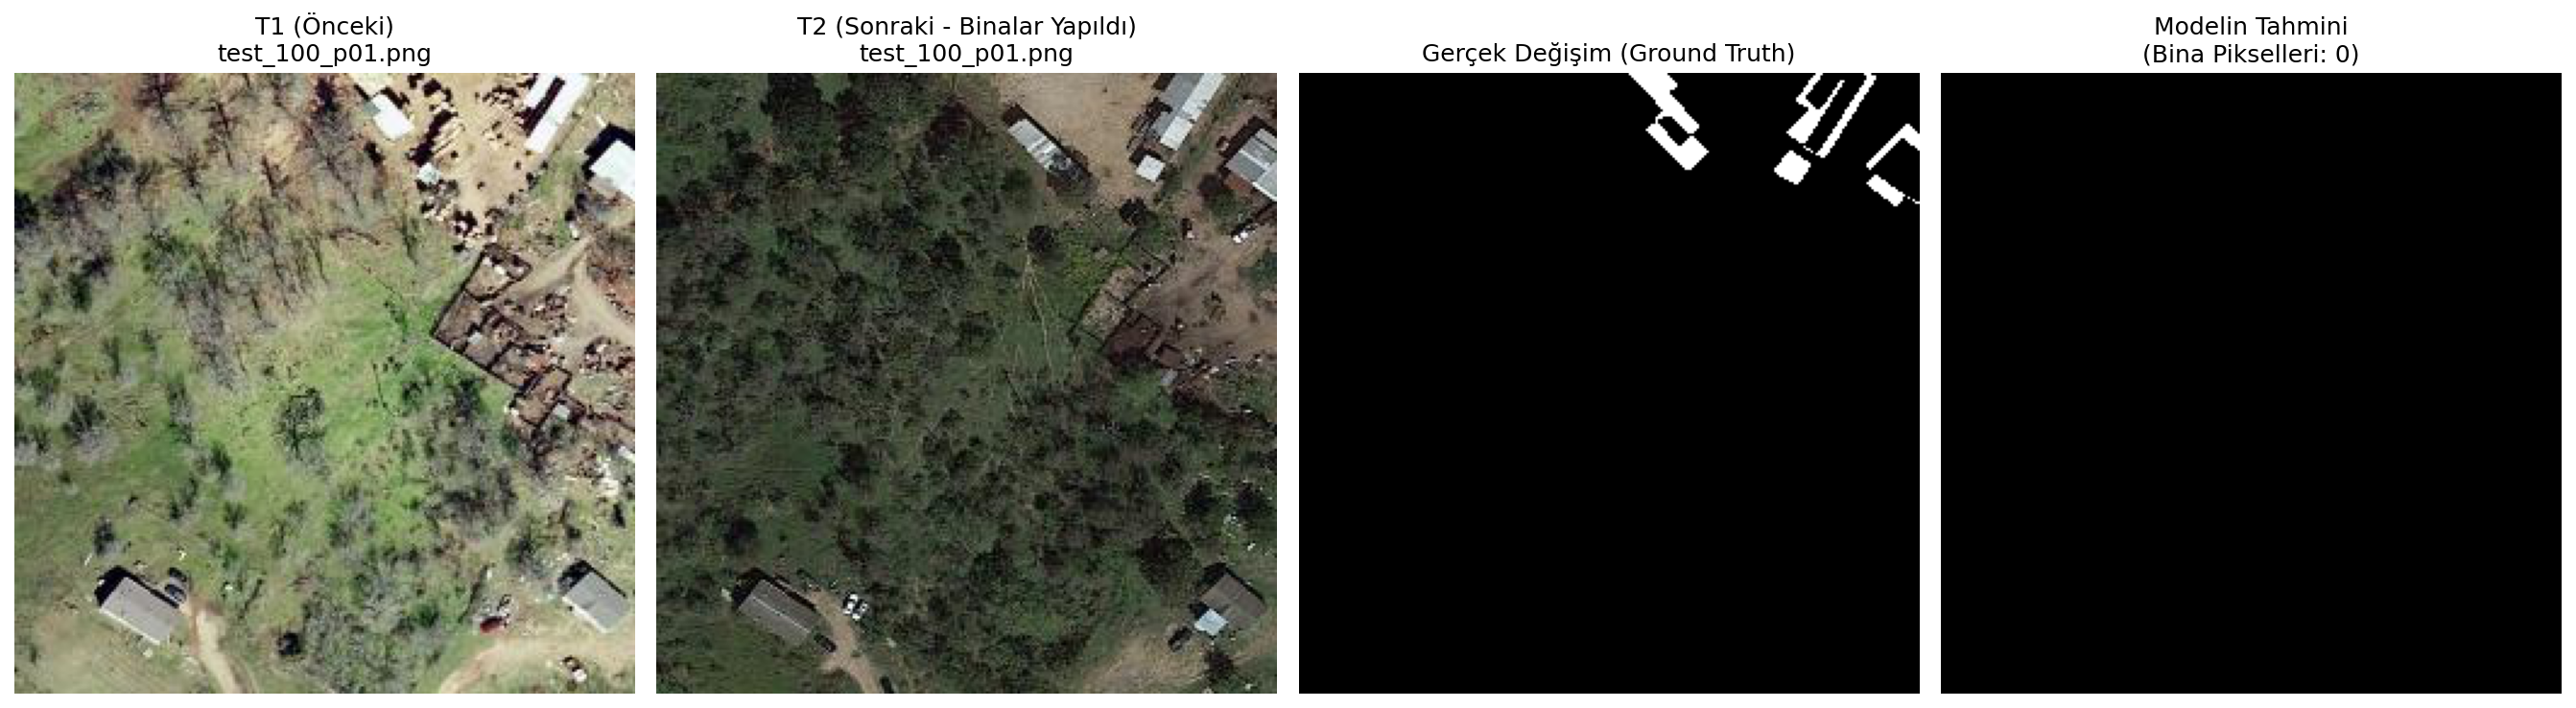

✅ Görsel başarıyla üretildi! Dosya: test_100_p01.png


In [16]:
import os, torch, cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.datasets import DualAugmentationDataset
from src.models.baseline_unet import BaselineEarlyFusionUNet

# 1. Modeli Yükle
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BaselineEarlyFusionUNet(encoder_name="resnet18", in_channels=6, classes=1).to(device)
ckpt = torch.load("/content/checkpoints/baseline_early_fusion_resnet18/best_model.pth", map_location=device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

# 2. Test setini tara ve İÇİNDE BİNA OLAN bir kare bul
ds = DualAugmentationDataset(root_dir="/content/remote-sensing-change-detection/data/processed", split="test")

found = False
for idx in range(len(ds)):
    item = ds[idx]
    # İçinde en az 500 piksel bina olan ilk kareyi yakala
    if item["raw_mask"].sum() > 500:
        with torch.no_grad():
            t1 = item["t1"].unsqueeze(0).to(device)
            t2 = item["t2"].unsqueeze(0).to(device)
            prob = torch.sigmoid(model(t1, t2)).squeeze().cpu().numpy()
            pred = (prob > 0.5).astype(np.uint8)

        # 3. Görseli Hazırla ve Kaydet
        fig, axes = plt.subplots(1, 4, figsize=(18, 5))
        axes[0].imshow(item["raw_t1"]); axes[0].set_title(f"T1 (Önceki)\n{item['filename']}")
        axes[1].imshow(item["raw_t2"]); axes[1].set_title(f"T2 (Sonraki - Binalar Yapıldı)\n{item['filename']}")
        axes[2].imshow(item["raw_mask"] * 255, cmap="gray"); axes[2].set_title("Gerçek Değişim (Ground Truth)")
        axes[3].imshow(pred * 255, cmap="gray"); axes[3].set_title(f"Modelin Tahmini\n(Bina Pikselleri: {pred.sum()})")
        for ax in axes: ax.axis("off")

        plt.tight_layout()
        save_path = "/content/gercek_kanit.png"
        plt.savefig(save_path, bbox_inches="tight", dpi=150)
        plt.close()

        # 4. Ekrana Bas
        display(Image(save_path))
        print(f"✅ Görsel başarıyla üretildi! Dosya: {item['filename']}")
        found = True
        break

if not found:
    print("Binalı kare bulunamadı.")

In [17]:
import os, shutil
from google.colab import files

paket_klasoru = "/content/baseline_sonuclari"
os.makedirs(paket_klasoru, exist_ok=True)
ckpt_dir = "/content/checkpoints/baseline_early_fusion_resnet18"

# 1. Başarısızlık Örneği (Failure Case)
if os.path.exists("/content/gercek_kanit.png"):
    shutil.copy("/content/gercek_kanit.png", os.path.join(paket_klasoru, "baseline_failure_case.png"))

# 2. Başarılı Test Örnekleri, Eğitim Grafiği ve Metrikler
for dosya in ["test_examples.png", "loss_curve.png", "history.csv", "test_metrics.json"]:
    yol = os.path.join(ckpt_dir, dosya)
    if os.path.exists(yol):
        shutil.copy(yol, paket_klasoru)

# Ziple ve bilgisayarına indir
shutil.make_archive("/content/baseline_sonuclari", "zip", paket_klasoru)
files.download("/content/baseline_sonuclari.zip")
print("✅ Paket hazırlandı ve indiriliyor!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Paket hazırlandı ve indiriliyor!
